# HDB resale price classification - EDA
Run from the project root. Training uses categorical IDs; name mappings below are for exploratory plots only.

In [1]:
import numpy as np
import pandas as pd
from src.data_preparation import load_data, parse_remaining_lease, split_data

df = load_data("data/data.csv")
print(f"Shape after basic cleaning: {df.shape}")
df.head()


Shape after basic cleaning: (84465, 14)


,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,1
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,21,8,SENGKANG,Model A,0
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,0
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,12,8,HOUGANG,Model A,1
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,1


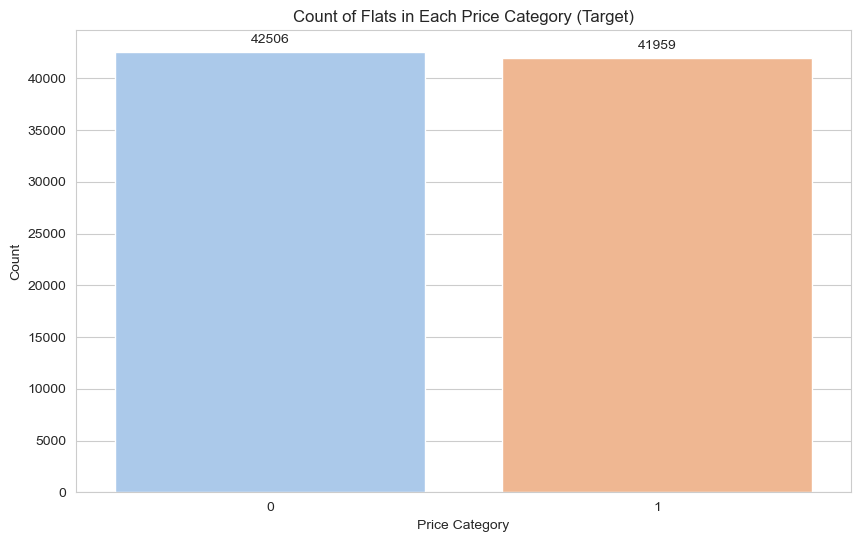

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for price category with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='price_category', hue='price_category', data=df, palette='pastel', legend=False)
plt.title('Count of Flats in Each Price Category (Target)')
plt.xlabel('Price Category')
plt.ylabel('Count')
#plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [3]:
# Target labels are validated and encoded by load_data.
df['price_category'].value_counts()


price_category
0    42506
1    41959
Name: count, dtype: int64

In [4]:
# 1. Inspect unique values and counts for flat_type specifically
print("--- Unique values in flat_type ---")
print(sorted(df["flat_type"].dropna().unique()))

print("\n--- Frequency count of flat_type ---")
print(df["flat_type"].value_counts(dropna=False))

print("\n" + "=" * 50 + "\n")

# 2. Inspect unique value counts across all categorical/text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    print(f"=== Column: {col} | Unique count: {df[col].nunique()} ===")
    print(df[col].value_counts(dropna=False))
    print("-" * 40)

--- Unique values in flat_type ---
['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE', 'FOUR ROOM', 'MULTI-GENERATION']

--- Frequency count of flat_type ---
flat_type
4 ROOM              33087
3 ROOM              21490
5 ROOM              20449
EXECUTIVE            6685
FOUR ROOM            1741
2 ROOM                944
1 ROOM                 38
MULTI-GENERATION       31
Name: count, dtype: int64


=== Column: month | Unique count: 54 ===
month
2018-07    2395
2018-08    1956
2019-05    1940
2018-10    1887
2018-09    1880
2018-06    1860
2017-05    1857
2017-11    1839
2017-08    1837
2019-04    1812
2019-06    1800
2018-03    1792
2016-08    1784
2017-03    1782
2018-11    1763
2016-06    1723
2016-04    1722
2018-04    1721
2016-05    1716
2017-04    1698
2017-07    1690
2017-10    1675
2017-06    1644
2015-10    1644
2018-05    1635
2015-06    1622
2016-10    1595
2017-09    1581
2016-09    1578
2016-03    1565
2019-03    1557
2015-04    1540
2016-11    1495
2016-07  

In [5]:
# Normalize flat type labels.
df['flat_type'] = df['flat_type'].replace({'FOUR ROOM': '4 ROOM'})

print("--- Updated flat_type counts ---")
print(df['flat_type'].value_counts(dropna=False))

--- Updated flat_type counts ---
flat_type
4 ROOM              34828
3 ROOM              21490
5 ROOM              20449
EXECUTIVE            6685
2 ROOM                944
1 ROOM                 38
MULTI-GENERATION       31
Name: count, dtype: int64


In [6]:
# Preview lease conversion without modifying the raw schema.
df["remaining_lease"].map(parse_remaining_lease).head(10)


0     843.0
1     972.0
2     990.0
3     804.0
4     890.0
5     736.0
6     889.0
7     764.0
8     792.0
9    1020.0
Name: remaining_lease, dtype: float64

In [7]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,1
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,21,8,SENGKANG,Model A,0
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,0
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,12,8,HOUGANG,Model A,1
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,1


In [8]:
# Explore missing display names; model features use categorical IDs.
df[["town_name", "flatm_name"]].isna().sum()


town_name     741
flatm_name    488
dtype: int64

In [9]:
# Normalize model display names for exploratory analysis only.
import numpy as np

target_col = "flatm_name"

df[target_col] = df[target_col].astype(str).str.strip().str.upper()

model_map = {
    "PREMIUM APARTMENT.": "PREMIUM APARTMENT",
    "MULTI GENERATION": "MULTI-GENERATION",
    "NAN": np.nan,
    "NONE": np.nan,
    "2-ROOM": np.nan,
}

df[target_col] = df[target_col].replace(model_map)

print(df[target_col].value_counts(dropna=False))

flatm_name
MODEL A                   26281
IMPROVED                  21290
NEW GENERATION            13023
PREMIUM APARTMENT          8758
SIMPLIFIED                 3690
APARTMENT                  3223
MAISONETTE                 2433
STANDARD                   2374
MODEL A2                   1254
DBSS                        925
NaN                         489
TYPE S1                     221
MODEL A-MAISONETTE          143
ADJOINED FLAT               137
TYPE S2                     110
TERRACE                      52
MULTI-GENERATION             31
IMPROVED-MAISONETTE          16
PREMIUM APARTMENT LOFT       10
PREMIUM MAISONETTE            5
Name: count, dtype: int64


## Feature distributions and readable category labels

These plots describe the cleaned dataset before splitting; they do not establish predictive performance. Full-dataset name dictionaries are used only for EDA labels. Learned preprocessing and model selection must use training data only.

In [10]:
from IPython.display import display
from src.data_preparation import engineer_features

eda_df = df.copy()  # Keep training inputs unchanged.
features = engineer_features(df, include_eda=True)
numeric_columns = ["floor_area_sqm", "remaining_lease_months", "lease_commence_date", "storey_midpoint"]
for column in numeric_columns:
    eda_df[column] = features[column]

name_dictionaries = {}
mapping_summary = []
for id_col, name_col in [("town_id", "town_name"), ("flatm_id", "flatm_name")]:
    names = eda_df[name_col].astype("string").str.strip().str.upper()
    names = names.replace({"": pd.NA, "NAN": pd.NA, "NONE": pd.NA})
    if name_col == "flatm_name":
        names = names.replace({"PREMIUM APARTMENT.": "PREMIUM APARTMENT",
                               "MULTI GENERATION": "MULTI-GENERATION", "2-ROOM": pd.NA})
    pairs = pd.DataFrame({id_col: eda_df[id_col], name_col: names}).dropna().drop_duplicates()
    conflicts = pairs.groupby(id_col)[name_col].nunique().loc[lambda counts: counts > 1]
    if not conflicts.empty:
        display(pairs[pairs[id_col].isin(conflicts.index)])
        raise ValueError(f"Conflicting names for {id_col}; review before mapping.")
    lookup = pairs.set_index(id_col)[name_col].to_dict()
    name_dictionaries[id_col] = lookup
    filled = names.fillna(eda_df[id_col].map(lookup))
    mapping_summary.append({"column": name_col, "dictionary_size": len(lookup),
                            "missing_before": int(names.isna().sum()),
                            "filled_from_id": int((names.isna() & filled.notna()).sum()),
                            "missing_after": int(filled.isna().sum())})
    fallback = "UNKNOWN (ID=" + eda_df[id_col].astype("string").fillna("MISSING") + ")"
    eda_df[name_col] = filled.fillna(fallback)

town_map = name_dictionaries["town_id"]
flatm_map = name_dictionaries["flatm_id"]
display(pd.DataFrame(mapping_summary))
display(eda_df[["town_id", "town_name", "flatm_id", "flatm_name"]].head())
display(eda_df[numeric_columns].describe().T)
display(eda_df[numeric_columns].isna().sum().rename("missing_count").to_frame())

,column,dictionary_size,missing_before,filled_from_id,missing_after
0,town_name,26,741,741,0
1,flatm_name,20,489,488,1


,town_id,town_name,flatm_id,flatm_name
0,17,PASIR RIS,5,IMPROVED
1,21,SENGKANG,8,MODEL A
2,9,CHOA CHU KANG,5,IMPROVED
3,12,HOUGANG,8,MODEL A
4,22,SERANGOON,5,IMPROVED


,count,mean,std,min,25%,50%,75%,max
floor_area_sqm,84465.0,97.518221,24.203556,31.0,76.0,96.0,112.0,280.0
remaining_lease_months,84465.0,891.199538,140.277464,559.0,789.0,880.0,996.0,1164.0
lease_commence_date,84465.0,1992.312603,11.728561,1966.0,1984.0,1992.0,2001.0,2016.0
storey_midpoint,84465.0,8.444504,5.603543,2.0,5.0,8.0,11.0,50.0


,missing_count
floor_area_sqm,0
remaining_lease_months,0
lease_commence_date,0
storey_midpoint,0


**Observation:** After normalizing name variants, each observed ID has at most one valid name. The table reports dictionary coverage, recovered names, and unresolved values.

**Modeling impact:** Town and flat-model IDs are categories, not ordered quantities. Names make frequencies interpretable.

**Decision:** Fill only missing names using unambiguous dictionaries, keep existing valid names, and explicitly label unresolved IDs. These dictionaries are not used by the training pipeline.

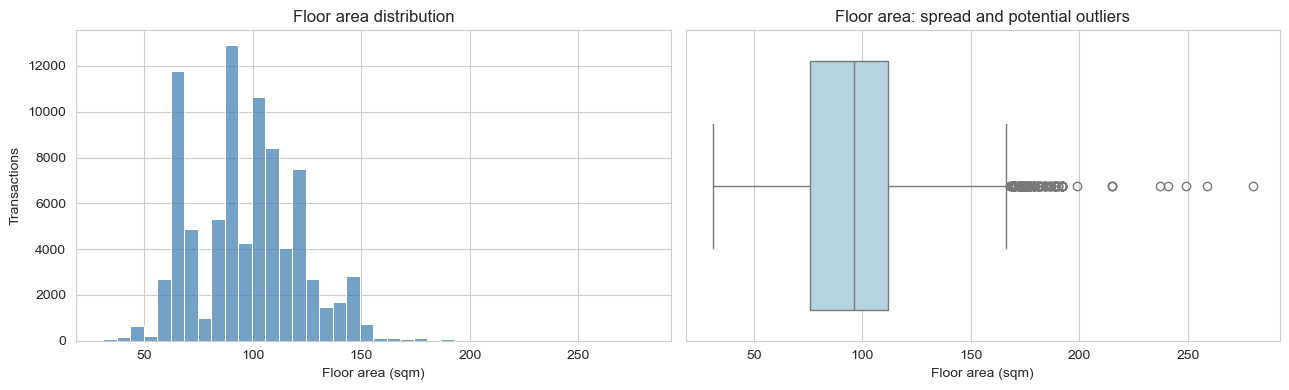

Range: 31-280 sqm; median: 96; IQR: 76-112; outside 1.5 IQR fences: 269


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=eda_df, x="floor_area_sqm", bins=40, ax=axes[0], color="steelblue")
axes[0].set(title="Floor area distribution", xlabel="Floor area (sqm)", ylabel="Transactions")
sns.boxplot(data=eda_df, x="floor_area_sqm", ax=axes[1], color="lightblue")
axes[1].set(title="Floor area: spread and potential outliers", xlabel="Floor area (sqm)")
plt.tight_layout()
plt.show()
area = eda_df["floor_area_sqm"]
q1, q3 = area.quantile([0.25, 0.75])
iqr = q3 - q1
print(f"Range: {area.min():.0f}-{area.max():.0f} sqm; median: {area.median():.0f}; "
      f"IQR: {q1:.0f}-{q3:.0f}; outside 1.5 IQR fences: "
      f"{((area < q1 - 1.5 * iqr) | (area > q3 + 1.5 * iqr)).sum():,}")

### Floor area: interpretation

**Observation:** Areas range from 31 to 280 sqm, with a median of 96 sqm and an interquartile range of 76-112 sqm. Boxplot outliers are candidates for inspection, not automatically errors.

**Modeling impact:** Extreme values can affect linear model fitting. Standardization changes scale but does not remove skew or outliers; trees do not require standardization.

**Decision:** Retain these values for now. Inspect extreme areas against flat type and source records before excluding them; assess any transformation with training-set cross-validation.

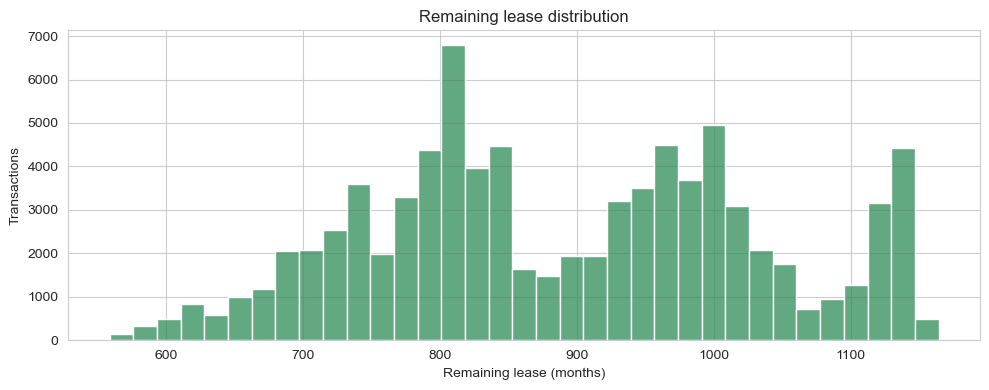

Range: 559-1164 months; median: 880; missing: 0


In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=eda_df, x="remaining_lease_months", bins=35, ax=ax, color="seagreen")
ax.set(title="Remaining lease distribution", xlabel="Remaining lease (months)", ylabel="Transactions")
plt.tight_layout()
plt.show()
lease = eda_df["remaining_lease_months"]
print(f"Range: {lease.min():.0f}-{lease.max():.0f} months; median: {lease.median():.0f}; missing: {lease.isna().sum():,}")

### Remaining lease: interpretation

**Observation:** Remaining leases range from 559 to 1,164 months; the median is 880 months. No values are missing after parsing in this dataset.

**Modeling impact:** Converting mixed numeric-year and year/month strings to months makes records comparable. This feature may overlap with commencement year and transaction date; its distribution alone does not establish predictive value.

**Decision:** Retain the month-based feature and shared parser. Check parsing failures on future data and evaluate redundancy using training data.

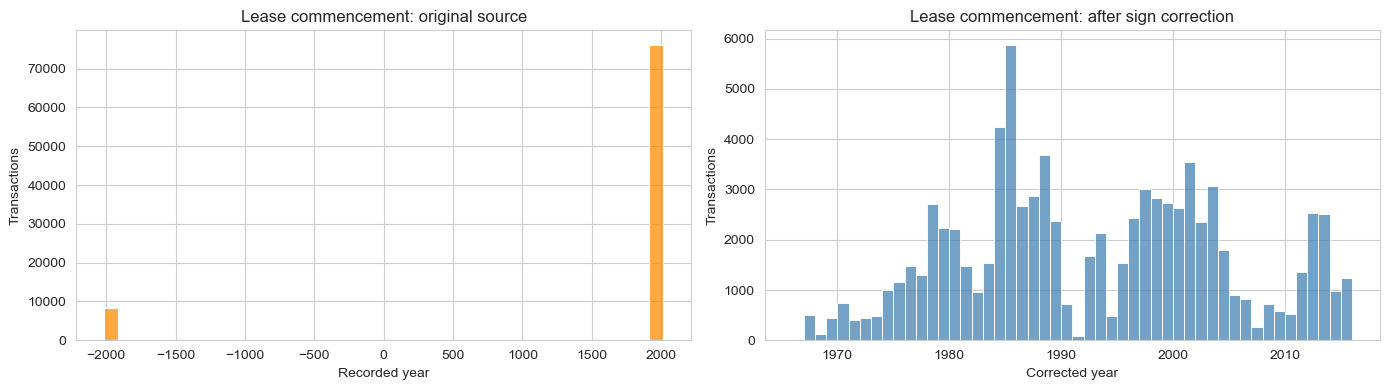

Original negative years: 8,446; corrected: 8,446
Remaining negative years: 0; missing years after cleaning: 0
Corrected year range: 1966-2016


,month,original_year,corrected_year
70,2016-12,-1995,1995
87,2017-11,-1997,1997
88,2018-03,-1997,1997
97,2018-11,-1980,1980
102,2015-04,-1986,1986
103,2016-09,-1987,1987
106,2015-08,-1987,1987
115,2015-01,-1996,1996
124,2015-08,-2008,2008
127,2016-05,-1988,1988


In [13]:
# Compare the untouched source with the corrected shared-cleaning output.
raw_year_data = pd.read_csv("data/data.csv").dropna(how="all").drop_duplicates()
raw_year = pd.to_numeric(raw_year_data["lease_commence_date"], errors="coerce")
year = eda_df["lease_commence_date"]
negative_source = raw_year.lt(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(x=raw_year, bins=40, ax=axes[0], color="darkorange")
axes[0].set(title="Lease commencement: original source", xlabel="Recorded year", ylabel="Transactions")
sns.histplot(x=year, binwidth=1, ax=axes[1], color="steelblue")
axes[1].set(title="Lease commencement: after sign correction", xlabel="Corrected year", ylabel="Transactions")
plt.tight_layout()
plt.show()
sale_year = pd.to_datetime(raw_year_data["month"], format="%Y-%m", errors="coerce").dt.year
recoverable = negative_source & raw_year.abs().between(1900, sale_year) & raw_year.abs().mod(1).eq(0)
print(f"Original negative years: {negative_source.sum():,}; corrected: {recoverable.sum():,}")
print(f"Remaining negative years: {year.lt(0).sum():,}; missing years after cleaning: {year.isna().sum():,}")
print(f"Corrected year range: {year.min():.0f}-{year.max():.0f}")
audit = raw_year_data.loc[negative_source, ["month", "lease_commence_date"]].copy()
audit = audit.rename(columns={"lease_commence_date": "original_year"})
audit["corrected_year"] = audit["original_year"].abs().where(recoverable)
display(audit.head(10))

### Lease commencement: interpretation

**Observation:** The source contains 8,446 negative commencement years (approximately 10% of cleaned records). All become integer years between 1967 and 2016 when their signs are reversed, and none exceeds its transaction year. The before/after plots show the original error and repaired distribution; no rows were removed for this correction.

**Modeling impact:** Negative years could distort scaling and create artificial boundaries in models that use commencement year. The current baseline excludes this field, so this repair supports EDA and data-quality auditing rather than directly changing baseline predictions.

**Decision:** Treat these records as sign errors and reverse negative signs only when the result is an integer between 1900 and the transaction year. Other negative values become missing in the audit/EDA representation. The current baseline omits commencement year entirely, so it is not imputed or encoded for model prediction. Keep the source CSV unchanged for auditability. This is a documented plausibility-based repair, not independent verification against source records.

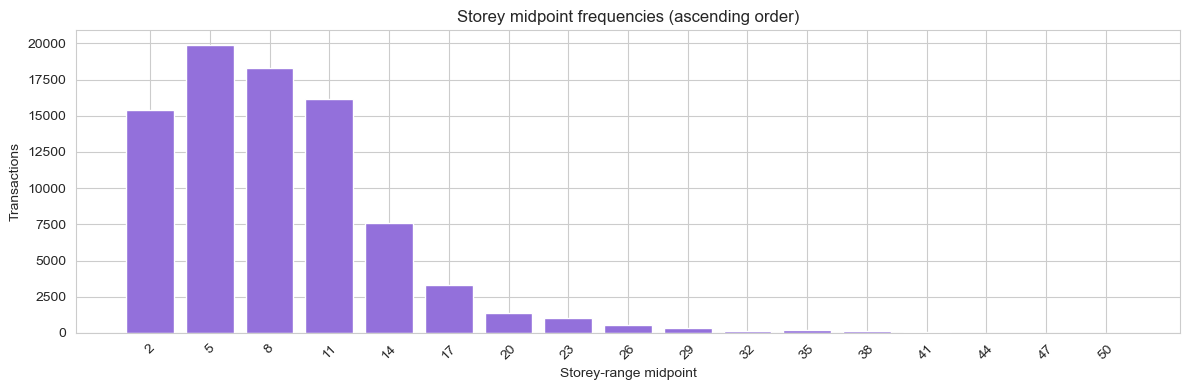

Most frequent midpoint: 5; range: 2-50; missing: 0


In [14]:
storey_counts = eda_df["storey_midpoint"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(storey_counts)), storey_counts.values, color="mediumpurple")
ax.set_xticks(range(len(storey_counts)), [f"{value:g}" for value in storey_counts.index], rotation=45)
ax.set(title="Storey midpoint frequencies (ascending order)", xlabel="Storey-range midpoint", ylabel="Transactions")
plt.tight_layout()
plt.show()
print(f"Most frequent midpoint: {storey_counts.idxmax():g}; range: {storey_counts.index.min():g}-{storey_counts.index.max():g}; missing: {eda_df['storey_midpoint'].isna().sum():,}")

### Storey midpoint: interpretation

**Observation:** Midpoints range from 2 to 50. The bars preserve numeric ordering and show how unevenly floor ranges are represented; the printout identifies the most frequent range midpoint.

**Modeling impact:** A midpoint approximates a range, not an exact floor. Logistic regression models a linear contribution; trees can learn thresholds.

**Decision:** Retain the midpoint as a baseline. Do not delete rare floors solely for low frequency or interpret gaps between bars as missing data. Compare alternative range encodings on training data.

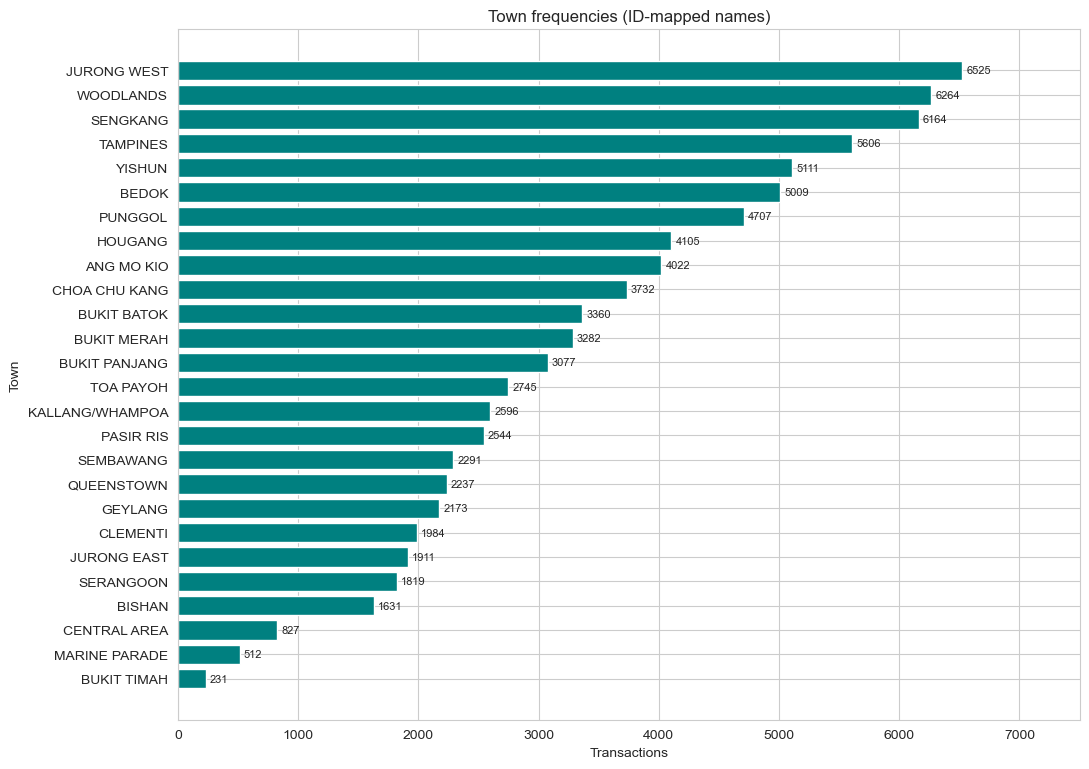

,transactions,share_pct
town_name,,
JURONG WEST,6525,7.73
WOODLANDS,6264,7.42
SENGKANG,6164,7.3
TAMPINES,5606,6.64
YISHUN,5111,6.05
BEDOK,5009,5.93
PUNGGOL,4707,5.57
HOUGANG,4105,4.86
ANG MO KIO,4022,4.76


In [15]:
counts = eda_df["town_name"].value_counts()
fig, ax = plt.subplots(figsize=(11, max(5, len(counts) * 0.3)))
ax.barh(counts.index.astype(str), counts.values, color="teal")
ax.invert_yaxis()
ax.set(title="Town frequencies (ID-mapped names)", xlabel="Transactions", ylabel="Town")
ax.bar_label(ax.containers[0], fmt="%d", padding=3, fontsize=8)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()
display(counts.rename("transactions").to_frame().assign(share_pct=lambda table: (100 * table.transactions / len(eda_df)).round(2)))

### Town: interpretation

**Observation:** There are 26 towns. JURONG WEST has the largest count (6,525; 7.73%), followed by WOODLANDS (6,264; 7.42%) and SENGKANG (6,164; 7.30%). BUKIT TIMAH has only 231 records (0.27%). All 741 missing town names were recovered from IDs.

**Modeling impact:** Unequal sample sizes mean estimates for rare categories have less supporting evidence. Frequencies alone do not show association with the target.

**Decision:** Keep categorical IDs for training and mapped names for interpretation. Inspect performance for smaller categories and consider grouping only if training-set validation supports it.

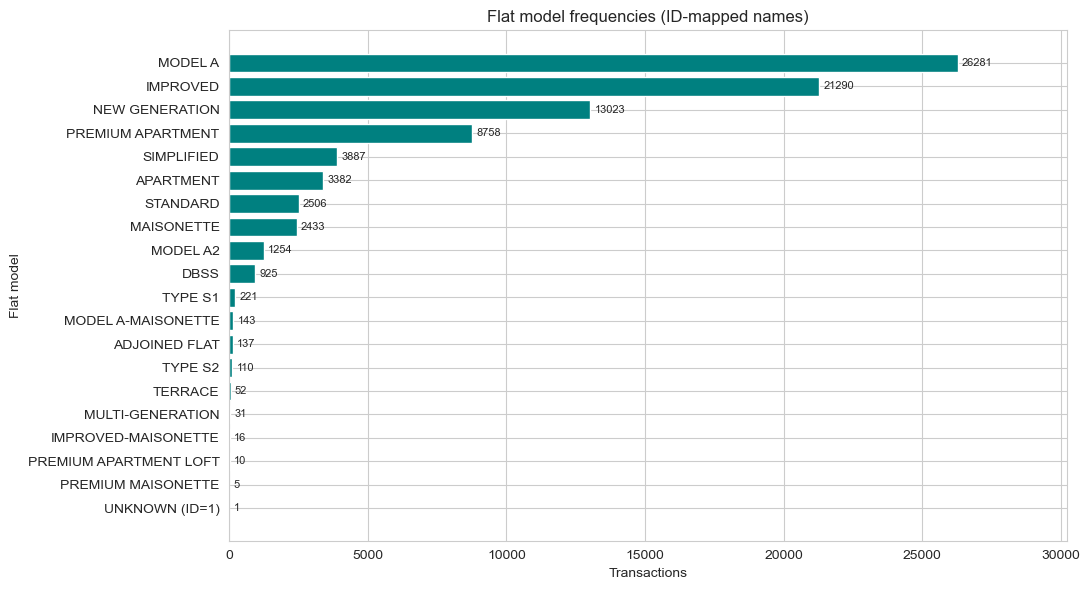

,transactions,share_pct
flatm_name,,
MODEL A,26281,31.11
IMPROVED,21290,25.21
NEW GENERATION,13023,15.42
PREMIUM APARTMENT,8758,10.37
SIMPLIFIED,3887,4.6
APARTMENT,3382,4.0
STANDARD,2506,2.97
MAISONETTE,2433,2.88
MODEL A2,1254,1.48


In [16]:
counts = eda_df["flatm_name"].value_counts()
fig, ax = plt.subplots(figsize=(11, max(5, len(counts) * 0.3)))
ax.barh(counts.index.astype(str), counts.values, color="teal")
ax.invert_yaxis()
ax.set(title="Flat model frequencies (ID-mapped names)", xlabel="Transactions", ylabel="Flat model")
ax.bar_label(ax.containers[0], fmt="%d", padding=3, fontsize=8)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()
display(counts.rename("transactions").to_frame().assign(share_pct=lambda table: (100 * table.transactions / len(eda_df)).round(2)))

### Flat model: interpretation

**Observation:** MODEL A (31.11%), IMPROVED (25.21%), and NEW GENERATION (15.42%) together account for 71.74% of records. Several categories are very rare. The dictionary recovers 488 missing names; one unresolved record remains explicitly labeled UNKNOWN (ID=1), rather than being discarded.

**Modeling impact:** Unequal sample sizes mean estimates for rare categories have less supporting evidence. Frequencies alone do not show association with the target.

**Decision:** Keep categorical IDs for training and mapped names for interpretation. Inspect performance for smaller categories and consider grouping only if training-set validation supports it.

## Fixed data split

The following shared split is fixed before target-conditioned analysis. All subsequent feature-versus-target plots use training rows only; validation and test rows are excluded.

In [17]:
import yaml

with open("src/config.yaml", encoding="utf-8") as stream:
    config = yaml.safe_load(stream)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df, config["split"])
print({"train": len(y_train), "validation": len(y_val), "test": len(y_test)})


{'train': 67572, 'validation': 8446, 'test': 8447}


## Numeric features versus target (training set only)

Compare the two target classes using unscaled, unimputed engineered training features. This preserves interpretable units. Validation and test sets are not used in any plot, statistic, or bin choice below.

Each feature has a grouped boxplot and a histogram with shared bin edges. Histogram densities are normalized separately within each class (`common_norm=False`), so each class has total area 1; heights represent density, not counts or the probability of Above Median. Boxplot outliers remain visible.

In [18]:
target_order = ["Below Median", "Above Median"]
target_palette = {"Below Median": "#3578A8", "Above Median": "#D87932"}
relationship_columns = ["floor_area_sqm", "remaining_lease_months", "lease_commence_date", "storey_midpoint"]
assert X_train.index.equals(y_train.index)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
relationship_df = X_train.reindex(columns=relationship_columns).copy()
# Commencement year is retained for EDA only, not baseline model inputs.
relationship_df["lease_commence_date"] = df.loc[X_train.index, "lease_commence_date"]
relationship_df["price_category"] = y_train.map({0: "Below Median", 1: "Above Median"})
assert relationship_df["price_category"].notna().all()
print(f"Training rows used: {len(relationship_df):,}")
display(relationship_df["price_category"].value_counts().reindex(target_order).rename("training_rows").to_frame())


def plot_numeric_by_target(column, label, bin_width=None):
    values = relationship_df[column].dropna()
    if values.empty:
        raise ValueError(f"No observed training values for {column}")
    if bin_width is None:
        bins = np.histogram_bin_edges(values, bins=35)
    else:
        # Align bins to integer years or the discrete floor-range midpoints.
        bins = np.arange(values.min() - bin_width / 2,
                         values.max() + bin_width, bin_width)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.boxplot(data=relationship_df, x="price_category", y=column,
                hue="price_category", order=target_order, hue_order=target_order,
                palette=target_palette, legend=False, ax=axes[0])
    axes[0].set(title=f"{label} by target - training only", xlabel="Price category", ylabel=label)
    sns.histplot(data=relationship_df, x=column, hue="price_category",
                 hue_order=target_order, palette=target_palette,
                 bins=bins, stat="density", common_norm=False,
                 multiple="layer", element="step", alpha=0.3, ax=axes[1])
    axes[1].set(title="Within-class normalized distributions - training only",
                xlabel=label, ylabel="Density (area = 1 per class)")
    plt.tight_layout()
    plt.show()
    summary = relationship_df.groupby("price_category")[column].agg(
        observed="count", median="median", mean="mean",
        q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
        missing=lambda s: s.isna().sum(),
    ).reindex(target_order)
    display(summary.round(2))
    return summary

Training rows used: 67,572


,training_rows
price_category,
Below Median,34005
Above Median,33567


### Floor area (sqm)

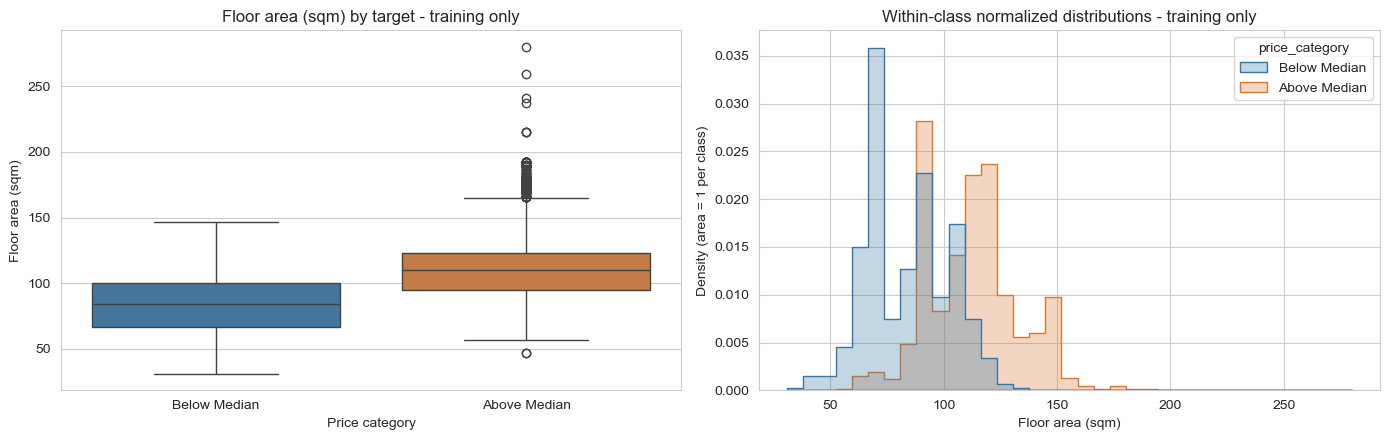

,observed,median,mean,q25,q75,missing
price_category,,,,,,
Below Median,34005,84.0,83.15,67.0,100.0,0
Above Median,33567,110.0,112.13,95.0,123.0,0


In [19]:
floor_area_sqm_target_summary = plot_numeric_by_target('floor_area_sqm', 'Floor area (sqm)', bin_width=None)

**Observation:** The median area is 110 sqm for Above Median versus 84 sqm for Below Median (a 26 sqm difference). The class means are 112.13 and 83.15 sqm, respectively.

**Modeling impact:** Larger areas are associated with the Above Median class in training data. The distribution overlap means area alone is not a perfect rule, and this association does not establish causality.

**Decision:** Retain floor area as a baseline feature. Keep training-fitted scaling for logistic regression, and do not derive a hard classification threshold from these plots.

### Remaining lease (months)

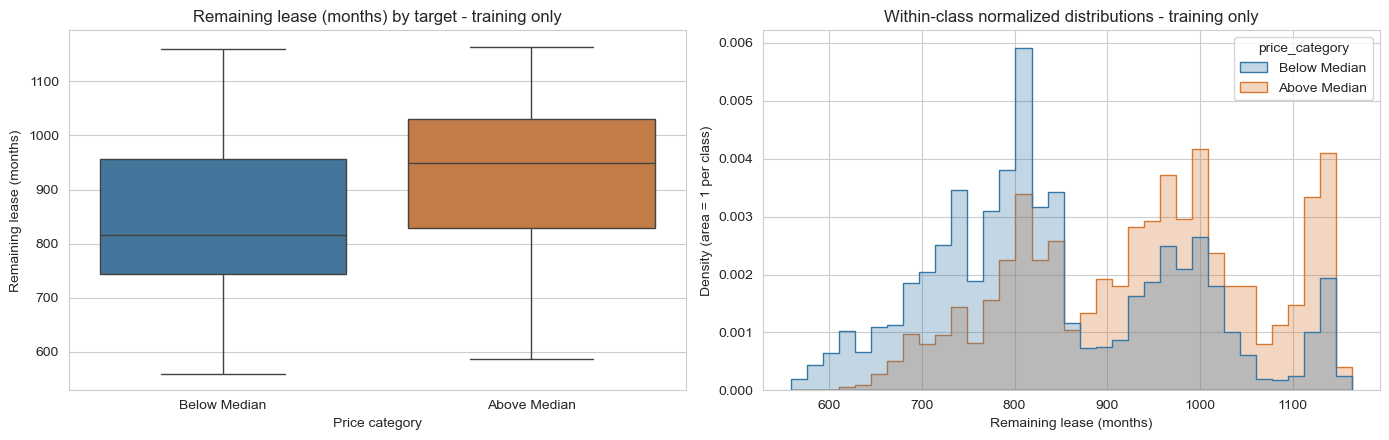

,observed,median,mean,q25,q75,missing
price_category,,,,,,
Below Median,34005,816.0,844.68,744.0,957.0,0
Above Median,33567,949.0,937.83,828.0,1031.0,0


In [20]:
remaining_lease_months_target_summary = plot_numeric_by_target('remaining_lease_months', 'Remaining lease (months)', bin_width=None)

**Observation:** The median remaining lease is 949 months for Above Median versus 816 months for Below Median, a difference of 133 months.

**Modeling impact:** The training groups differ in lease duration, suggesting potential classification information. Remaining lease may be redundant with commencement year and transaction date.

**Decision:** Retain the month-based feature for now. Compare feature ablations and redundancy using training-set cross-validation before removing or transforming it.

### Lease commencement year

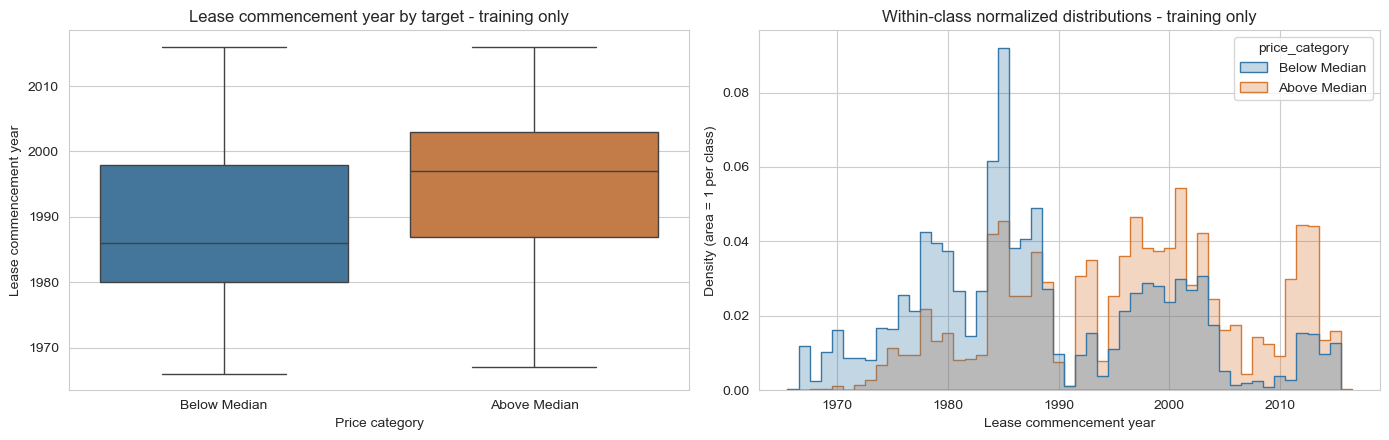

,observed,median,mean,q25,q75,missing
price_category,,,,,,
Below Median,34005,1986.0,1988.46,1980.0,1998.0,0
Above Median,33567,1997.0,1996.18,1987.0,2003.0,0


In [21]:
lease_commence_date_target_summary = plot_numeric_by_target('lease_commence_date', 'Lease commencement year', bin_width=1)

**Observation:** After the shared sign correction, the median commencement year is 1997 for Above Median versus 1986 for Below Median. Means are 1996.18 and 1988.46.

**Modeling impact:** Later commencement years are associated with Above Median in this training split. This can reflect multiple related attributes; it is not proof that changing lease year causes a price-category change.

**Decision:** Retain corrected commencement year for EDA only. Both baseline models exclude it because of its overlap with remaining lease; remaining lease and transaction timing remain model inputs.

### Storey-range midpoint

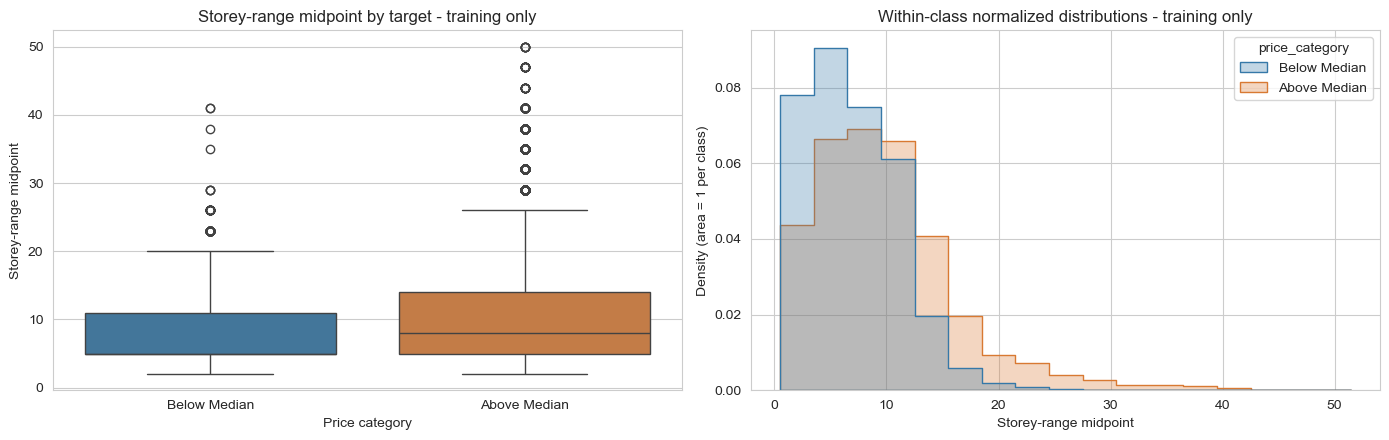

,observed,median,mean,q25,q75,missing
price_category,,,,,,
Below Median,34005,5.0,6.97,5.0,11.0,0
Above Median,33567,8.0,9.94,5.0,14.0,0


In [22]:
storey_midpoint_target_summary = plot_numeric_by_target('storey_midpoint', 'Storey-range midpoint', bin_width=3)

**Observation:** The median midpoint is 8 for Above Median versus 5 for Below Median. Means are 9.94 and 6.97, respectively. Both groups span multiple floor ranges.

**Modeling impact:** Higher floors are associated with Above Median on average, while class overlap limits separation by this feature alone. Midpoints approximate floor ranges rather than exact floors.

**Decision:** Retain the numeric midpoint baseline. Compare non-linear effects or alternative range encodings through training-set validation; avoid assigning arbitrary category thresholds from this plot.

### Scope of these findings

These are descriptive associations within the fixed training split, not measurements of model accuracy or causal effects. Group medians and histogram overlap do not establish which feature is most useful after accounting for the others. Use training-set cross-validation for transformations, feature selection, and model comparison. Keep the held-out test set out of those decisions.

## Town versus target (training set only)

The horizontal bars show the fraction of training transactions labeled Above Median within each town, sorted from highest to lowest. Labels include sample counts (`n`). The dashed line is the overall Above Median fraction in the training set. Town-name dictionaries below are built from training rows only, without target values; they are for display and are not model inputs.

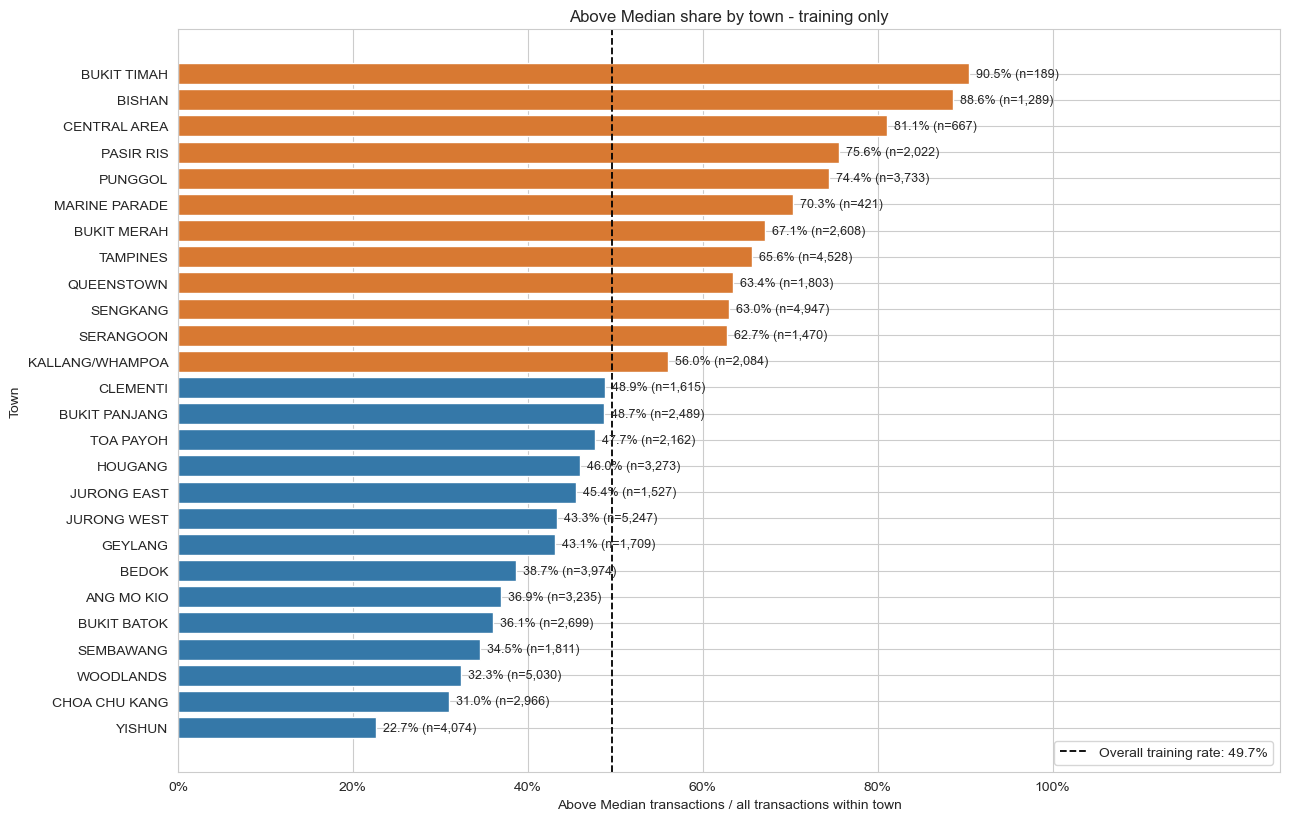

,town_name,n,above_count,above_rate,above_pct
town_id,,,,,
7,BUKIT TIMAH,189,171,0.904762,90.48
3,BISHAN,1289,1142,0.885958,88.60
8,CENTRAL AREA,667,541,0.811094,81.11
17,PASIR RIS,2022,1528,0.755687,75.57
18,PUNGGOL,3733,2778,0.744174,74.42
16,MARINE PARADE,421,296,0.703088,70.31
5,BUKIT MERAH,2608,1750,0.671012,67.10
23,TAMPINES,4528,2971,0.656140,65.61
19,QUEENSTOWN,1803,1144,0.634498,63.45


In [23]:
from matplotlib.ticker import PercentFormatter

assert X_train.index.equals(y_train.index)
train_towns = df.loc[X_train.index, ["town_id", "town_name"]].copy()
train_towns["town_name"] = train_towns["town_name"].astype("string").str.strip().str.upper().replace("", pd.NA)
name_pairs = train_towns[["town_id", "town_name"]].dropna().drop_duplicates()
conflicts = name_pairs.groupby("town_id")["town_name"].nunique()
if conflicts.gt(1).any():
    raise ValueError("Conflicting town names in training rows; review before mapping.")
train_town_map = name_pairs.set_index("town_id")["town_name"].to_dict()
train_towns["town_name"] = train_towns["town_name"].fillna(train_towns["town_id"].map(train_town_map))
train_towns["town_name"] = train_towns["town_name"].fillna(
    "UNKNOWN (ID=" + train_towns["town_id"].astype("string").fillna("MISSING") + ")"
)
train_towns["above_median"] = y_train
# Group by ID to keep distinct towns separate even if display names coincide.
town_target_summary = train_towns.groupby("town_id", dropna=False).agg(
    town_name=("town_name", "first"), n=("above_median", "size"),
    above_count=("above_median", "sum"), above_rate=("above_median", "mean"),
).sort_values(["above_rate", "n"], ascending=[False, False])
assert town_target_summary["n"].sum() == len(X_train)
assert town_target_summary["above_count"].sum() == y_train.sum()
training_above_rate = y_train.mean()

fig, ax = plt.subplots(figsize=(13, max(6, len(town_target_summary) * 0.32)))
positions = np.arange(len(town_target_summary))
colors = np.where(town_target_summary["above_rate"] >= training_above_rate, "#D87932", "#3578A8")
ax.barh(positions, town_target_summary["above_rate"], color=colors)
ax.set_yticks(positions, town_target_summary["town_name"])
ax.invert_yaxis()
ax.axvline(training_above_rate, color="black", linestyle="--", linewidth=1.3,
           label=f"Overall training rate: {training_above_rate:.1%}")
for position, row in enumerate(town_target_summary.itertuples()):
    ax.text(row.above_rate + 0.008, position, f"{row.above_rate:.1%} (n={row.n:,})",
            va="center", fontsize=9)
ax.set_xlim(0, 1.26)  # Annotation margin beyond the 0-100% data range.
ax.set_xticks(np.linspace(0, 1, 6))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title="Above Median share by town - training only",
       xlabel="Above Median transactions / all transactions within town", ylabel="Town")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(town_target_summary.assign(above_pct=lambda table: (100 * table.above_rate).round(2)))

In [24]:
from IPython.display import Markdown

highest = town_target_summary.iloc[0]
lowest = town_target_summary.iloc[-1]
display(Markdown(
    f"**Observation:** In training data, {highest['town_name']} has the highest Above Median share "
    f"({highest['above_rate']:.1%}, n={int(highest['n']):,}), while {lowest['town_name']} has the lowest "
    f"({lowest['above_rate']:.1%}, n={int(lowest['n']):,}). The overall training share is {training_above_rate:.1%}. "
    "Use the sample counts when interpreting differences: rates from smaller groups are less stable.\n\n"
    "**Modeling impact:** The variation suggests town may carry classification information, but the plot does not "
    "isolate a causal location effect. Towns also differ in area, flat type, lease duration, and transaction timing. "
    "Interpretation additionally depends on how the source defined the median threshold; that process has not been verified.\n\n"
    "**Decision:** Retain town ID as a one-hot categorical baseline and compare a model without town using training-set "
    "cross-validation. These target-derived town rates are descriptive only and are not fed back into model features. "
    "Validation and test rows are excluded from the aggregation and display-name dictionary."
))

**Observation:** In training data, BUKIT TIMAH has the highest Above Median share (90.5%, n=189), while YISHUN has the lowest (22.7%, n=4,074). The overall training share is 49.7%. Use the sample counts when interpreting differences: rates from smaller groups are less stable.

**Modeling impact:** The variation suggests town may carry classification information, but the plot does not isolate a causal location effect. Towns also differ in area, flat type, lease duration, and transaction timing. Interpretation additionally depends on how the source defined the median threshold; that process has not been verified.

**Decision:** Retain town ID as a one-hot categorical baseline and compare a model without town using training-set cross-validation. These target-derived town rates are descriptive only and are not fed back into model features. Validation and test rows are excluded from the aggregation and display-name dictionary.

## Feature relationships and potential redundancy (training only)

This section uses the fixed training rows only. Correlation and category composition describe overlapping information, not whether a feature can safely be removed. These analyses do not use target values; model-based ablation should subsequently use training-set cross-validation.

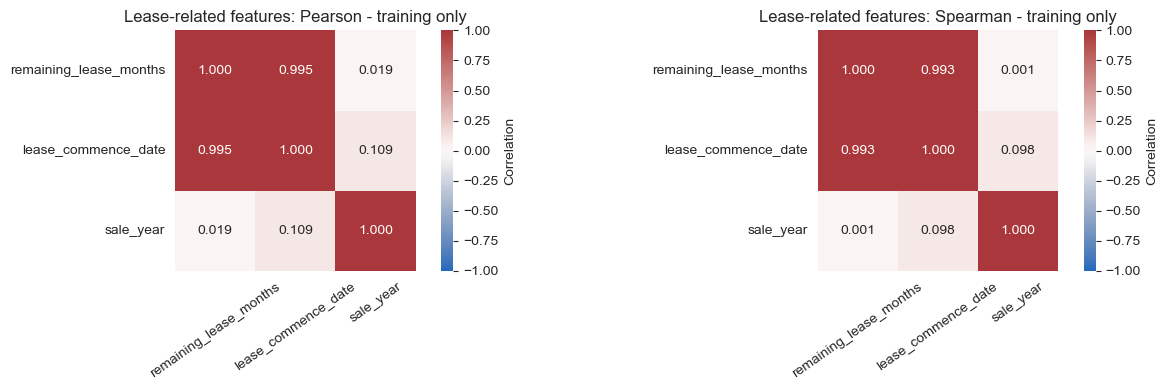

,remaining_lease_months,lease_commence_date,sale_year
remaining_lease_months,1.000000,0.995216,0.018562
lease_commence_date,0.995216,1.000000,0.108545
sale_year,0.018562,0.108545,1.000000


,remaining_lease_months,lease_commence_date,sale_year
remaining_lease_months,1.000000,0.993015,0.001324
lease_commence_date,0.993015,1.000000,0.098437
sale_year,0.001324,0.098437,1.000000


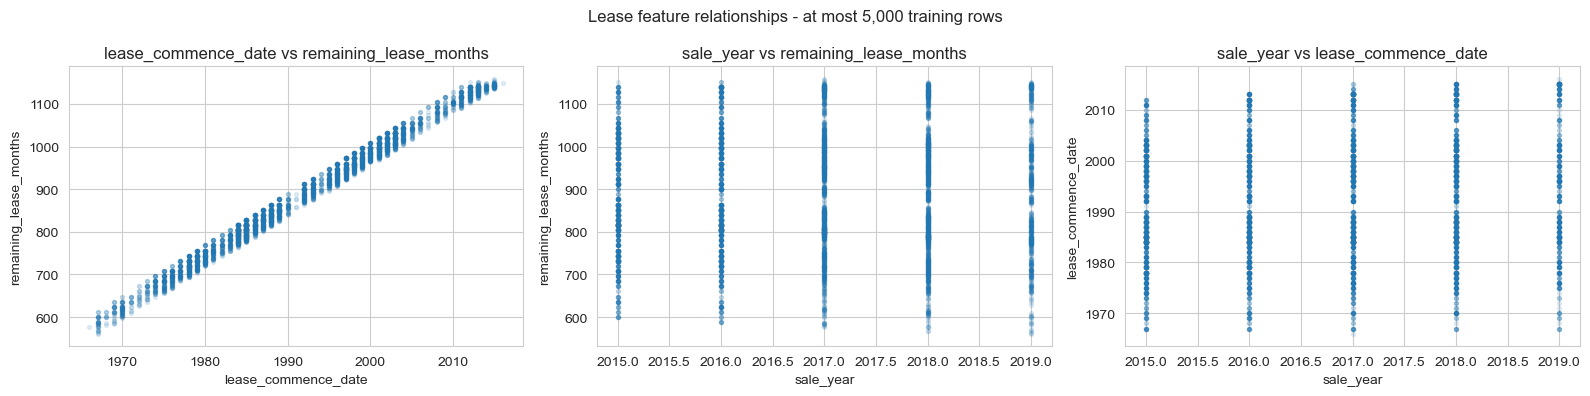

**Observation:** Remaining lease and commencement year have Pearson r=0.995 and Spearman rho=0.993. The matrices also report each relationship with transaction year; scatterplots show whether the associations follow a narrow band or broader structure.

**Modeling impact:** Remaining lease and commencement year express related lease-age information. Transaction year helps interpret that relationship, but pairwise correlations alone cannot establish a deterministic formula or redundancy.

**Decision:** Exclude `lease_commence_date` from both baseline models to simplify the overlapping lease information. Retain `remaining_lease_months` for its finer temporal resolution, together with `sale_year` and `sale_month` to represent transaction timing. Keep commencement year in EDA for interpretation and data-quality checks. This change has been implemented and both models retrained; a paired comparison using identical training cross-validation folds is still needed to assess its performance impact.

In [25]:
lease_columns = ["remaining_lease_months", "lease_commence_date", "sale_year"]
lease_train = X_train.reindex(columns=lease_columns).copy()
lease_train["lease_commence_date"] = df.loc[X_train.index, "lease_commence_date"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = lease_train.corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1,
                square=True, ax=ax, cbar_kws={"label": "Correlation"})
    ax.set_title(f"Lease-related features: {method.title()} - training only")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
display(lease_train.corr(method="pearson"))
display(lease_train.corr(method="spearman"))

# Sample only training rows for display; correlations above use all training rows.
scatter_sample = lease_train.sample(n=min(5000, len(lease_train)), random_state=42)
pairs = [("lease_commence_date", "remaining_lease_months"),
         ("sale_year", "remaining_lease_months"),
         ("sale_year", "lease_commence_date")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(scatter_sample[x], scatter_sample[y], s=8, alpha=0.12, rasterized=True)
    ax.set(xlabel=x, ylabel=y, title=f"{x} vs {y}")
fig.suptitle("Lease feature relationships - at most 5,000 training rows")
plt.tight_layout()
plt.show()
pearson_lease = lease_train.corr().loc["remaining_lease_months", "lease_commence_date"]
spearman_lease = lease_train.corr(method="spearman").loc["remaining_lease_months", "lease_commence_date"]
display(Markdown(
    f"**Observation:** Remaining lease and commencement year have Pearson r={pearson_lease:.3f} "
    f"and Spearman rho={spearman_lease:.3f}. The matrices also report each relationship with transaction year; "
    "scatterplots show whether the associations follow a narrow band or broader structure.\n\n"
    "**Modeling impact:** Remaining lease and commencement year express related lease-age information. "
    "Transaction year helps interpret that relationship, but pairwise correlations alone cannot establish a deterministic formula or redundancy.\n\n"
    '**Decision:** Exclude `lease_commence_date` from both baseline models to simplify the overlapping lease information. Retain `remaining_lease_months` for its finer temporal resolution, together with `sale_year` and `sale_month` to represent transaction timing. Keep commencement year in EDA for interpretation and data-quality checks. This change has been implemented and both models retrained; a paired comparison using identical training cross-validation folds is still needed to assess its performance impact.'
))

### Flat type and floor area

Boxplots and within-type summaries reveal whether flat type is merely a substitute for area or whether each type still contains substantial size variation. Type ordering below is a display choice, not ordinal model encoding.

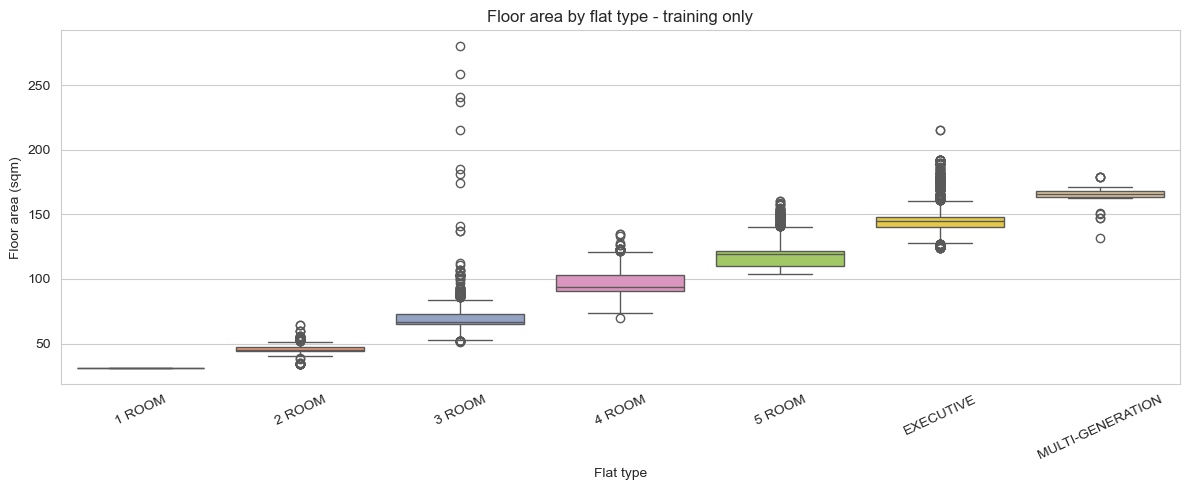

,n,median,mean,minimum,maximum,q25,q75
flat_type,,,,,,,
1 ROOM,35,31.0,31.00,31.0,31.0,31.00,31.00
2 ROOM,751,45.0,45.50,34.0,64.0,44.00,47.00
3 ROOM,17206,67.0,68.36,51.0,280.0,65.00,73.00
4 ROOM,27838,94.0,95.86,70.0,135.0,91.00,103.00
5 ROOM,16352,119.0,118.25,104.0,160.0,110.00,122.00
EXECUTIVE,5364,145.0,144.21,124.0,215.0,140.00,148.00
MULTI-GENERATION,26,166.0,163.92,132.0,179.0,163.25,168.25


**Observation:** Between-type mean differences account for 90.0% of the observed training area variation (descriptive eta-squared). The table and boxplots show within-type ranges, IQRs, and sample sizes, including rare types. This is not a price-prediction score.

**Modeling impact:** Flat type and area can share substantial size information, while within-type size variation means they need not be interchangeable. A category can also express distinctions beyond area.

**Decision:** Keep both initially. Compare removing flat type while retaining area, and the reverse, with identical training CV folds. Small groups should not drive cleaning rules based on their boxplots alone.

In [26]:
type_area_train = X_train[["flat_type", "floor_area_sqm"]].copy()
type_area_train["flat_type"] = type_area_train["flat_type"].fillna("UNKNOWN")
preferred_types = ["1 ROOM", "2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE", "MULTI-GENERATION"]
observed_types = type_area_train["flat_type"].unique()
type_order = [t for t in preferred_types if t in observed_types] + sorted(set(observed_types) - set(preferred_types))
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=type_area_train, x="flat_type", y="floor_area_sqm", order=type_order,
            hue="flat_type", hue_order=type_order, palette="Set2", legend=False, ax=ax)
ax.set(title="Floor area by flat type - training only", xlabel="Flat type", ylabel="Floor area (sqm)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
type_area_summary = type_area_train.groupby("flat_type")["floor_area_sqm"].agg(
    n="count", median="median", mean="mean", minimum="min", maximum="max",
    q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75),
).reindex(type_order)
display(type_area_summary.round(2))
# Descriptive fraction of observed area variation between the type means.
valid_area = type_area_train.dropna(subset=["floor_area_sqm"])
group_stats = valid_area.groupby("flat_type")["floor_area_sqm"].agg(["count", "mean"])
grand_mean = valid_area["floor_area_sqm"].mean()
total_ss = ((valid_area["floor_area_sqm"] - grand_mean) ** 2).sum()
between_ss = (group_stats["count"] * (group_stats["mean"] - grand_mean) ** 2).sum()
area_eta_squared = between_ss / total_ss if total_ss > 0 else float("nan")
display(Markdown(
    f"**Observation:** Between-type mean differences account for {area_eta_squared:.1%} of the observed "
    "training area variation (descriptive eta-squared). The table and boxplots show within-type ranges, IQRs, "
    "and sample sizes, including rare types. This is not a price-prediction score.\n\n"
    "**Modeling impact:** Flat type and area can share substantial size information, while within-type size variation "
    "means they need not be interchangeable. A category can also express distinctions beyond area.\n\n"
    "**Decision:** Keep both initially. Compare removing flat type while retaining area, and the reverse, with identical "
    "training CV folds. Small groups should not drive cleaning rules based on their boxplots alone."
))

### Flat type x flat model: counts and normalized composition

The count heatmap shows sample support. The row-normalized heatmap answers: **within each flat type, what fraction belongs to each flat model?** Both use the same rows and columns. Normalization here is for plotting, not feature scaling, label cleanup, or a change to one-hot model inputs.

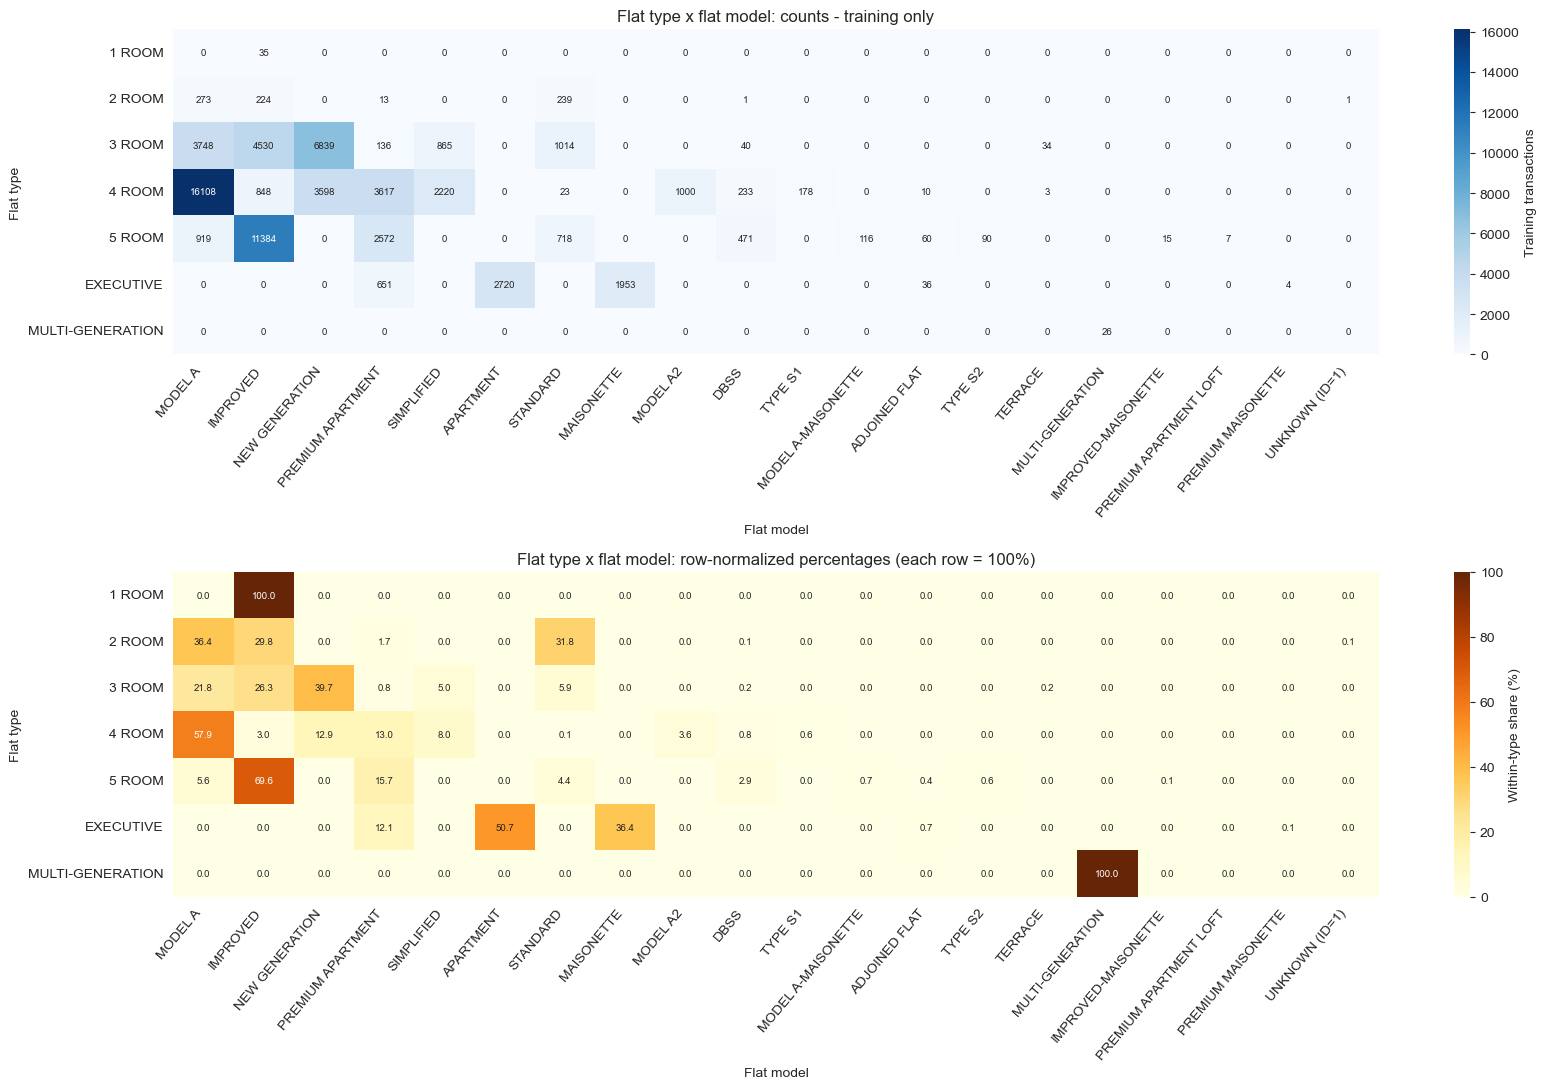

flatm_name,MODEL A,IMPROVED,NEW GENERATION,PREMIUM APARTMENT,SIMPLIFIED,APARTMENT,STANDARD,MAISONETTE,MODEL A2,DBSS,TYPE S1,MODEL A-MAISONETTE,ADJOINED FLAT,TYPE S2,TERRACE,MULTI-GENERATION,IMPROVED-MAISONETTE,PREMIUM APARTMENT LOFT,PREMIUM MAISONETTE,UNKNOWN (ID=1)
flat_type,,,,,,,,,,,,,,,,,,,,
1 ROOM,0,35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2 ROOM,273,224,0,13,0,0,239,0,0,1,0,0,0,0,0,0,0,0,0,1
3 ROOM,3748,4530,6839,136,865,0,1014,0,0,40,0,0,0,0,34,0,0,0,0,0
4 ROOM,16108,848,3598,3617,2220,0,23,0,1000,233,178,0,10,0,3,0,0,0,0,0
5 ROOM,919,11384,0,2572,0,0,718,0,0,471,0,116,60,90,0,0,15,7,0,0
EXECUTIVE,0,0,0,651,0,2720,0,1953,0,0,0,0,36,0,0,0,0,0,4,0
MULTI-GENERATION,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,26,0,0,0,0


flatm_name,MODEL A,IMPROVED,NEW GENERATION,PREMIUM APARTMENT,SIMPLIFIED,APARTMENT,STANDARD,MAISONETTE,MODEL A2,DBSS,TYPE S1,MODEL A-MAISONETTE,ADJOINED FLAT,TYPE S2,TERRACE,MULTI-GENERATION,IMPROVED-MAISONETTE,PREMIUM APARTMENT LOFT,PREMIUM MAISONETTE,UNKNOWN (ID=1)
flat_type,,,,,,,,,,,,,,,,,,,,
1 ROOM,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2 ROOM,36.4,29.8,0.0,1.7,0.0,0.0,31.8,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
3 ROOM,21.8,26.3,39.7,0.8,5.0,0.0,5.9,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0
4 ROOM,57.9,3.0,12.9,13.0,8.0,0.0,0.1,0.0,3.6,0.8,0.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5 ROOM,5.6,69.6,0.0,15.7,0.0,0.0,4.4,0.0,0.0,2.9,0.0,0.7,0.4,0.6,0.0,0.0,0.1,0.0,0.0,0.0
EXECUTIVE,0.0,0.0,0.0,12.1,0.0,50.7,0.0,36.4,0.0,0.0,0.0,0.0,0.7,0.0,0.0,0.0,0.0,0.0,0.1,0.0
MULTI-GENERATION,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0


,n,observed_models,most_common_model,most_common_model_pct
flat_type,,,,
1 ROOM,35,1,IMPROVED,100.0
2 ROOM,751,6,MODEL A,36.4
3 ROOM,17206,8,NEW GENERATION,39.7
4 ROOM,27838,11,MODEL A,57.9
5 ROOM,16352,10,IMPROVED,69.6
EXECUTIVE,5364,5,APARTMENT,50.7
MULTI-GENERATION,26,1,MULTI-GENERATION,100.0


In [27]:
# Build readable model labels strictly from training data, without target values.
train_models = df.loc[X_train.index, ["flatm_id", "flatm_name"]].copy()
names = train_models["flatm_name"].astype("string").str.strip().str.upper().replace({
    "": pd.NA, "NAN": pd.NA, "NONE": pd.NA,
    "PREMIUM APARTMENT.": "PREMIUM APARTMENT", "MULTI GENERATION": "MULTI-GENERATION", "2-ROOM": pd.NA,
})
model_pairs = pd.DataFrame({"flatm_id": train_models["flatm_id"], "flatm_name": names}).dropna().drop_duplicates()
if model_pairs.groupby("flatm_id")["flatm_name"].nunique().gt(1).any():
    raise ValueError("Conflicting flat-model names in training data.")
train_model_map = model_pairs.set_index("flatm_id")["flatm_name"].to_dict()
model_labels = names.fillna(train_models["flatm_id"].map(train_model_map))
model_labels = model_labels.fillna("UNKNOWN (ID=" + train_models["flatm_id"].astype("string").fillna("MISSING") + ")")
type_model_counts = pd.crosstab(type_area_train["flat_type"], model_labels).reindex(type_order, fill_value=0)
# Put frequent models first, retaining every observed category.
model_order = type_model_counts.sum().sort_values(ascending=False).index
type_model_counts = type_model_counts[model_order]
type_model_row_pct = type_model_counts.div(type_model_counts.sum(axis=1), axis=0) * 100
assert type_model_counts.to_numpy().sum() == len(X_train)
assert np.allclose(type_model_row_pct.sum(axis=1), 100)
fig, axes = plt.subplots(2, 1, figsize=(17, 11))
sns.heatmap(type_model_counts, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            cbar_kws={"label": "Training transactions"}, annot_kws={"fontsize": 7})
axes[0].set(title="Flat type x flat model: counts - training only", xlabel="Flat model", ylabel="Flat type")
sns.heatmap(type_model_row_pct, annot=True, fmt=".1f", cmap="YlOrBr", vmin=0, vmax=100,
            ax=axes[1], cbar_kws={"label": "Within-type share (%)"}, annot_kws={"fontsize": 7})
axes[1].set(title="Flat type x flat model: row-normalized percentages (each row = 100%)",
            xlabel="Flat model", ylabel="Flat type")
for ax in axes:
    ax.tick_params(axis="x", rotation=50)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()
display(type_model_counts)
display(type_model_row_pct.round(1))
dominant_models = pd.DataFrame({
    "n": type_model_counts.sum(axis=1),
    "observed_models": type_model_counts.gt(0).sum(axis=1),
    "most_common_model": type_model_counts.idxmax(axis=1),
    "most_common_model_pct": type_model_row_pct.max(axis=1).round(1),
})
display(dominant_models)

**Observation:** Most common flat types contain several flat models: 3 ROOM spans 8 observed model categories, 4 ROOM spans 11, and 5 ROOM spans 10. MODEL A accounts for 57.9% of 4 ROOM records, while IMPROVED accounts for 69.6% of 5 ROOM records. The single-model groups (1 ROOM and MULTI-GENERATION) contain only 35 and 26 training records, respectively. Thus these fields are not globally interchangeable. Raw counts give larger flat-type groups more visual weight. Row percentages make composition comparable across groups of different sizes. The dominant-model table reports how many models occur within each type and whether one category dominates; always read percentages alongside `n`, especially for rare flat types.

**Modeling impact:** If a type occurs with several model categories, the two features are not an exact one-to-one mapping. Even an apparently deterministic relationship in a small sample is insufficient evidence for dropping a feature. Shared information does not imply equal usefulness for the target.

**Decision:** Use row normalization for the composition plot, while keeping the count heatmap to show support. Do not normalize numeric IDs or replace one-hot encoding with these percentages. Preserve flat type and model ID in the baseline; decide whether to remove either through training-set cross-validation, using the same folds and metric.

### Data-quality follow-up

The area summary also exposes a 280 sqm training record labeled `3 ROOM`. Flag this combination for source verification before deciding whether the area or type is incorrect. An unusual combination is not sufficient evidence to overwrite a label or delete a record.

## Baseline feature decision

Exclude `lease_commence_date` from both baseline models due to its strong overlap with remaining lease. Keep `remaining_lease_months`, `sale_year`, and `sale_month`. Commencement year remains available for cleaning audits and the EDA plots above, but is absent from the training feature matrix and fitted encoders. Differences between lease duration and commencement year also depend on transaction timing, not only month-versus-year precision. This is a feature simplification decision, not evidence that predictive performance improves.

## Canonical category IDs and evaluation policy

Both models one-hot encode `town_id` and `flatm_id` after shared canonicalization: `17`, `17.0`, `"17"`, and `"17.0"` represent the same category. Missing IDs remain missing; invalid/non-integer IDs raise an error. Display-name dictionaries remain for EDA only.

Run `python main.py` for training-only stratified cross-validation (default 5 folds) and validation metrics. Each CV fold fits the entire preprocessing/classifier pipeline independently, and both models use identical fold settings. The saved model is fitted on the full training partition; this command does not search hyperparameters or score test labels.

Use `python main.py --model logistic_regression --final-test` only after freezing model choices. Earlier development runs already inspected the test partition; the switch prevents repeated routine test scoring but does not make that partition untouched again. Historical tree-search AUC values are not current CV results. This notebook's feature analysis continues to exclude held-out rows.

In [28]:
from src.data_preparation import normalize_category_id

id_examples = [17, 17.0, "17", "17.0", " 017.00 "]
id_canonicalization = pd.DataFrame({
    "input_representation": [repr(value) for value in id_examples],
    "canonical_id": [normalize_category_id(value) for value in id_examples],
})
assert id_canonicalization["canonical_id"].eq("17").all()
display(id_canonicalization)
# Regression suite additionally verifies both labels and probabilities for both models:
# python -m unittest discover -s tests -v

,input_representation,canonical_id
0,17,17
1,17.0,17
2,'17',17
3,'17.0',17
4,' 017.00 ',17
